Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Epoch 1, Training loss 0.7083,Validation loss 0.7124
Epoch 1000, Training loss 0.0709,Validation loss 0.0847
Epoch 2000, Training loss 0.0571,Validation loss 0.0746
Epoch 3000, Training loss 0.0523,Validation loss 0.0717
Accuracy: 0.9649122807017544
Precision: 0.8947368421052632
Recall: 1.0
F1: 0.9444444444444444


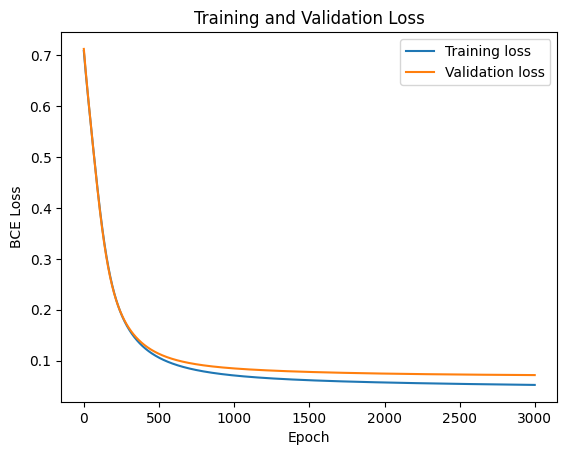

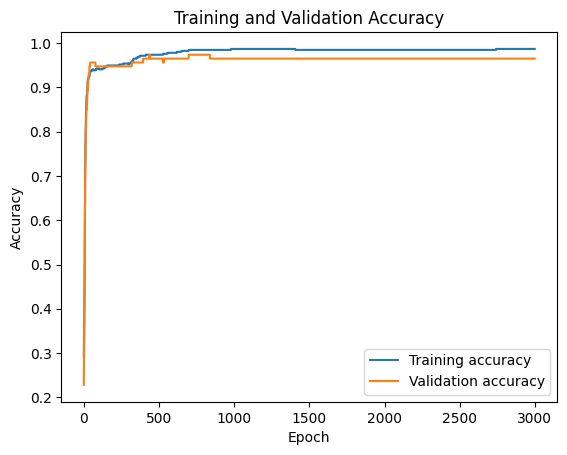

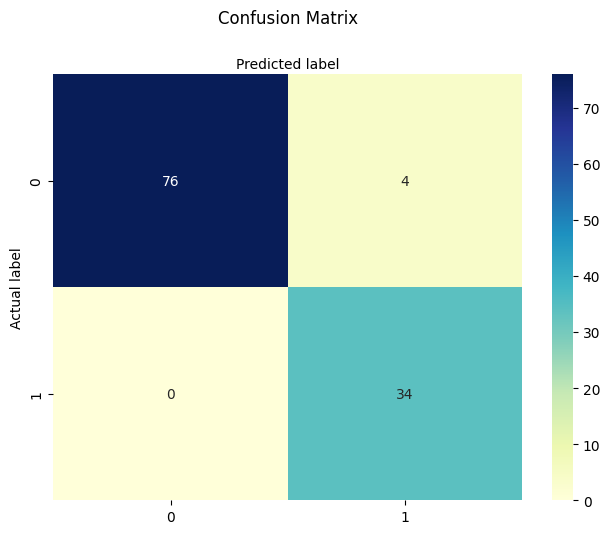

In [ ]:
import torch
import torch.nn as nn
import torch.optim as optim
import numpy as np
import pandas as pd
from google.colab import drive
import matplotlib.pyplot as plt
from sklearn import metrics
from collections import OrderedDict

drive.mount('/content/drive')
file_path = '/content/drive/MyDrive/Machine Learning/Cancer.csv'
Cancer = pd.DataFrame(pd.read_csv(file_path))

def binary_map(x):
  return x.map({'M': 1, 'B': 0})

Cancer[['diagnosis']] = Cancer[['diagnosis']].apply(binary_map)

X = Cancer.iloc[:, 2:32].values
Y = Cancer.iloc[:, 1].values

from sklearn.model_selection import train_test_split
X_train, X_test, Y_train, Y_test = train_test_split(X, Y, train_size = 0.8,
                                                    test_size = 0.2, random_state = 4)

from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()

X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

X_train = torch.tensor(X_train, dtype=torch.float32)
X_test = torch.tensor(X_test, dtype=torch.float32)
Y_train = torch.tensor(Y_train, dtype=torch.float32).reshape(-1,1)
Y_test = torch.tensor(Y_test, dtype=torch.float32).reshape(-1,1)

seq_model = nn.Sequential(OrderedDict([('hidden_linear1', nn.Linear(30,40)),
                                       ('hidden_activation1', nn.Tanh()),
                                       ('hidden_linear2', nn.Linear(40,40)),
                                       ('hidden_activation2', nn.Tanh()),
                                       ('output_linear', nn.Linear(40,1))]))

optimizer = optim.SGD(seq_model.parameters(), lr=0.01)

def training_loop(n_epochs, optimizer, model, loss_fn, X_train, Y_train, X_test, Y_test):

  train_losses = []
  test_losses = []
  train_losses = []
  test_losses = []
  train_accs = []
  test_accs = []
  for epoch in range(1, n_epochs + 1):
    prediction = model(X_train)
    loss_train = loss_fn(prediction, Y_train)
    validation = model(X_test)
    loss_test = loss_fn(validation, Y_test)

    optimizer.zero_grad()
    loss_train.backward()
    optimizer.step()

    train_losses.append(loss_train.item())
    test_losses.append(loss_test.item())

    if epoch == 1 or epoch % 1000 == 0:
      print(f"Epoch {epoch}, Training loss {loss_train.item():.4f},"
            f"Validation loss {loss_test.item():.4f}")
    train_acc = ((torch.sigmoid(prediction) >= 0.5).float() == Y_train).float().mean().item()
    test_acc = ((torch.sigmoid(validation) >= 0.5).float() == Y_test).float().mean().item()
    train_accs.append(train_acc)
    test_accs.append(test_acc)
  return train_losses, test_losses, train_accs, test_accs

train_losses, test_losses, train_accs, test_accs = training_loop(3000, optimizer, seq_model,
              nn.BCEWithLogitsLoss(), X_train, Y_train, X_test, Y_test )

with torch.no_grad():
    Y_pred = (torch.sigmoid(seq_model(X_test)) >= 0.5).float()

print("Accuracy:", metrics.accuracy_score(Y_test, Y_pred))
print("Precision:", metrics.precision_score(Y_test, Y_pred))
print("Recall:", metrics.recall_score(Y_test, Y_pred))
print("F1:", metrics.f1_score(Y_test, Y_pred))

plt.plot(train_losses, label='Training loss')
plt.plot(test_losses, label='Validation loss')
plt.xlabel('Epoch')
plt.ylabel('BCE Loss')
plt.title('Training and Validation Loss')
plt.legend()
plt.show()

plt.plot(train_accs, label='Training accuracy')
plt.plot(test_accs, label='Validation accuracy')
plt.xlabel('Epoch')
plt.ylabel('Accuracy')
plt.title('Training and Validation Accuracy')
plt.legend()
plt.show()

import seaborn as sns

cm = metrics.confusion_matrix(Y_test, Y_pred)
class_names = [0,1]

fig, ax = plt.subplots()
tick_marks = np.arange(len(class_names))
plt.xticks(tick_marks, class_names)
plt.yticks(tick_marks, class_names)

sns.heatmap(pd.DataFrame(cm), annot=True, cmap="YlGnBu", fmt='g')
ax.xaxis.set_label_position("top")
plt.tight_layout()
plt.title('Confusion Matrix', y=1.1)
plt.ylabel('Actual label')
plt.xlabel('Predicted label')
plt.show()